تجهيز مكتبات العمل

In [1]:
import requests
from bs4 import BeautifulSoup
import time
import pandas as pd

In [2]:

url = "https://books.toscrape.com/catalogue/page-1.html"
r = requests.get(url, timeout=10)
r.encoding = "utf-8"
print(r.status_code)

soup = BeautifulSoup(r.text, "html.parser")
books = soup.select("article.product_pod")
print(len(books))

200
20


سحب اول كتاب

In [3]:
book = books[0]
print({
    "Title": book.h3.a["title"],
    "Price": book.select_one("p.price_color").text,
    "Rating": book.select_one("p.star-rating")["class"][1],
    "Availability": book.select_one("p.availability").text.strip(),
    "URL": book.h3.a["href"],
})

{'Title': 'A Light in the Attic', 'Price': '£51.77', 'Rating': 'Three', 'Availability': 'In stock', 'URL': 'a-light-in-the-attic_1000/index.html'}


In [4]:
rows = []

for page in range(1, 51):
    url = f"https://books.toscrape.com/catalogue/page-{page}.html"
    r = requests.get(url, timeout=10)
    r.encoding = "utf-8"

    if r.status_code != 200:
        print(f"Page {page} failed: {r.status_code}")
        break

    soup = BeautifulSoup(r.text, "html.parser")
    for book in soup.select("article.product_pod"):
        rows.append({
            "Title": book.h3.a["title"],
            "Price": book.select_one("p.price_color").text,
            "Rating": book.select_one("p.star-rating")["class"][1],
            "Availability": book.select_one("p.availability").text.strip(),
            "URL": "https://books.toscrape.com/catalogue/" + book.h3.a["href"],
        })

    time.sleep(0.5)

تجميع الكتب وبدء عمليه EDA

In [5]:
df = pd.DataFrame(rows)
print(df.shape)

(1000, 5)


In [6]:
df.head()

,Title,Price,Rating,Availability,URL
0,A Light in the Attic,£51.77,Three,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,£53.74,One,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,£50.10,One,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,£47.82,Four,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock,https://books.toscrape.com/catalogue/sapiens-a...


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Title         1000 non-null   object
 1   Price         1000 non-null   object
 2   Rating        1000 non-null   object
 3   Availability  1000 non-null   object
 4   URL           1000 non-null   object
dtypes: object(5)
memory usage: 39.2+ KB


تنظيف البيانات والتعديل قبل التحليل

In [8]:
rating_map = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

In [9]:
df["Rating"] = df["Rating"].map(rating_map)

In [10]:
df["Price"] = df["Price"].str.replace("£", "").astype(float)

In [11]:
df[["Rating","Price" ]]

,Rating,Price
0,3,51.77
1,1,53.74
2,1,50.10
3,4,47.82
4,5,54.23
...,...,...
995,1,55.53
996,4,57.06
997,5,16.97
998,1,53.98


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Title         1000 non-null   object 
 1   Price         1000 non-null   float64
 2   Rating        1000 non-null   int64  
 3   Availability  1000 non-null   object 
 4   URL           1000 non-null   object 
dtypes: float64(1), int64(1), object(3)
memory usage: 39.2+ KB


In [13]:
df["Availability"].value_counts()

,count
Availability,
In stock,1000


In [14]:
df['Title'].duplicated().sum()


np.int64(1)

In [15]:
df[df["Title"].duplicated(keep=False)]

,Title,Price,Rating,Availability,URL
236,The Star-Touched Queen,46.02,5,In stock,https://books.toscrape.com/catalogue/the-star-...
358,The Star-Touched Queen,32.30,5,In stock,https://books.toscrape.com/catalogue/the-star-...


النظره الاحصائيه علي البيانات

In [16]:
df.describe()

,Price,Rating
count,1000.00000,1000.000000
mean,35.07035,2.923000
std,14.44669,1.434967
min,10.00000,1.000000
25%,22.10750,2.000000
50%,35.98000,3.000000
75%,47.45750,4.000000
max,59.99000,5.000000


In [17]:
df["Price"].corr(df["Rating"])

np.float64(0.028166239485873015)

مكتبات الرسوم البيانيه

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

Boxplot  لنظره اعمق ومعرفة وجود قيم شاذه

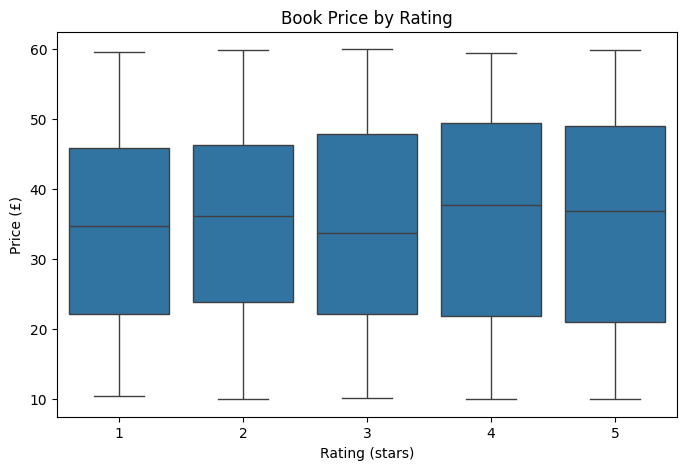

In [19]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Rating", y="Price")
plt.title("Book Price by Rating")
plt.xlabel("Rating (stars)")
plt.ylabel("Price (£)")
plt.show()

توزيع اسعار الكتب

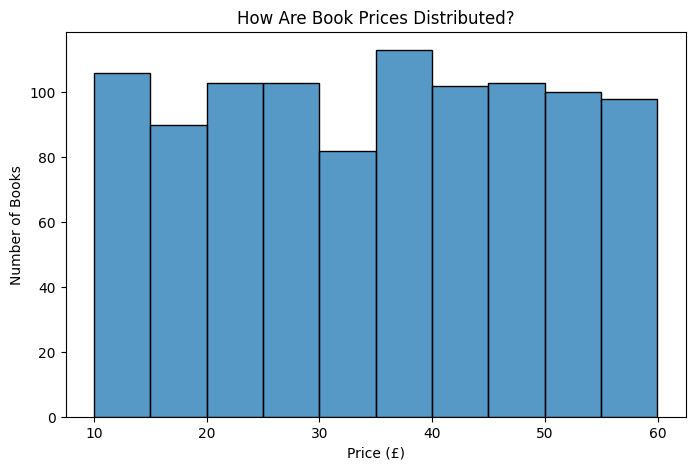

In [20]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Price", bins=10)
plt.title("How Are Book Prices Distributed?")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")
plt.show()

عدد الكتب لكل تقييم

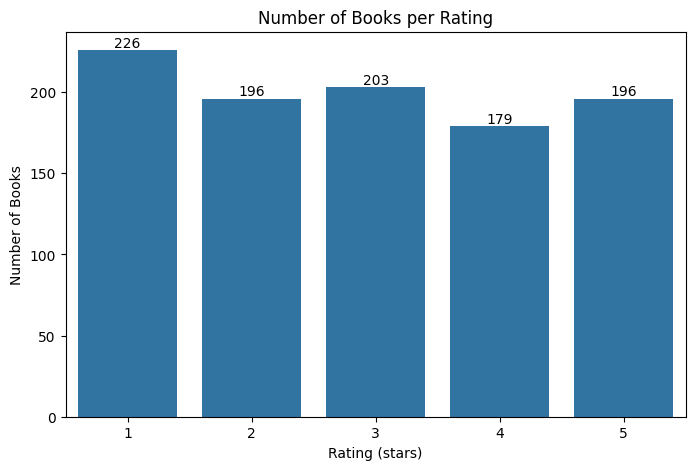

In [21]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x="Rating")
ax.bar_label(ax.containers[0])
plt.title("Number of Books per Rating")
plt.xlabel("Rating (stars)")
plt.ylabel("Number of Books")
plt.show()

اضافة عمود الفئات قبل الDounat

In [22]:
df["Price Tier"] = pd.cut(df["Price"], bins=[0, 20, 40, 60],
                          labels=["Cheap (<£20)", "Mid (£20-40)", "Premium (>£40)"])

الكتب لكل فئه سعريه

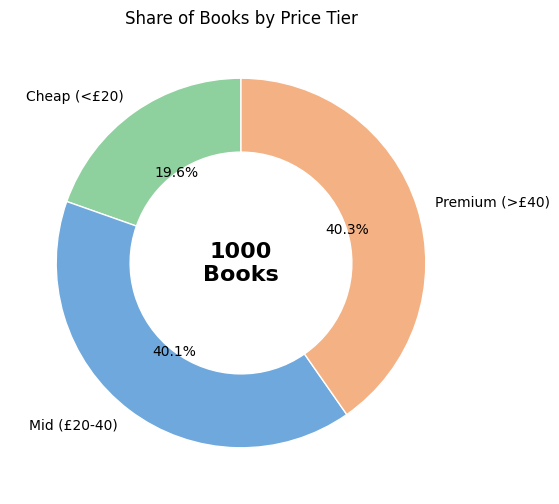

In [23]:
tier_counts = df["Price Tier"].value_counts().sort_index()

plt.figure(figsize=(6, 6))
plt.pie(
    tier_counts,
    labels=tier_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#8fd19e", "#6fa8dc", "#f4b183"],
    wedgeprops={"width": 0.4, "edgecolor": "white"},
)
plt.title("Share of Books by Price Tier")
plt.text(0, 0, f"{len(df)}\nBooks", ha="center", va="center", fontsize=16, fontweight="bold")
plt.show()

In [24]:
df.columns

Index(['Title', 'Price', 'Rating', 'Availability', 'URL', 'Price Tier'], dtype='object')

In [25]:
df.head()

,Title,Price,Rating,Availability,URL,Price Tier
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...,Premium (>£40)
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...,Premium (>£40)
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...,Premium (>£40)
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...,Premium (>£40)
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...,Premium (>£40)
